# سوق العقار السعودي: وين تطلع الأسعار؟

في هذا المشروع أشتغل على صفقات البيع العقارية المسجلة في وزارة العدل من 2020 إلى 2026. أبي أفهم كيف تختلف أسعار المتر بين المدن والأحياء، وكيف تغيّرت مع الوقت، وفي الأخير أحاول أبني نموذج يتوقع سعر المتر.

**المصدر:** بيانات وزارة العدل المفتوحة (منصة البيانات المفتوحة السعودية)، استخدمت النسخة المجمّعة في مستودع [saudi-real-estate-data](https://github.com/civillizard/saudi-real-estate-data).

## الجزء الأول: تجميع البيانات وتنظيفها

In [1]:
# download only the sales folder (the full repo is large)
!git clone -q --depth 1 --filter=blob:none --sparse https://github.com/civillizard/saudi-real-estate-data
%cd saudi-real-estate-data
!git sparse-checkout set moj/sales
%cd ..

In [2]:
import glob
import pandas as pd
import numpy as np
pd.set_option('display.float_format', '{:,.2f}'.format)

files = sorted(glob.glob('saudi-real-estate-data/moj/sales/MOJ-Sales-20*.csv*'))
print(len(files), 'files')

25 files


### الأعمدة مو ثابتة بين الملفات
أول ما فتحت الملفات لاحظت إن أسماء الأعمدة تتغيّر. أغلب الملفات فيها 10 أعمدة، بس ملفات 2023 مختلفة: الربع الأول فيه أعمدة زيادة (المخطط، رقم القطعة، سعر المتر)، والحي فيه منفصل عن المدينة. فسويت دالة توحّد كل ملف على نفس الأعمدة قبل ما أجمعهم.

In [3]:
rename = {
    'المنطقة': 'region', 'المدينة': 'city', 'المدينة / الحي': 'city_district', 'الحي': 'district',
    'الرقم المرجعي للصفقة': 'ref', 'رقم مرجعي': 'ref',
    'تاريخ الصفقة ميلادي': 'date', 'التاريخ': 'date',
    'تصنيف العقار': 'classification', 'نوع العقار': 'property_type', 'عدد العقارات': 'n_properties',
    'السعر': 'price', 'السعر بالريال السعودي': 'price', 'المساحة': 'area',
}

def load(f):
    d = pd.read_csv(f, dtype=str)
    d.columns = d.columns.str.strip()
    d = d.rename(columns=rename)
    if 'district' not in d:
        # 'الرياض/السويدى' -> 'السويدى'
        d['district'] = d['city_district'].str.split('/', n=1).str[-1]
    d['district'] = d['district'].str.replace('حي/', '', regex=False)
    d['quarter_file'] = f.split('MOJ-Sales-')[1][:7]
    cols = ['ref', 'region', 'city', 'district', 'date', 'classification', 'n_properties', 'price', 'area', 'quarter_file']
    return d.reindex(columns=cols)

raw = pd.concat([load(f) for f in files], ignore_index=True)
print(raw.shape)
raw.head()

(1444719, 10)


,ref,region,city,district,date,classification,n_properties,price,area,quarter_file
0,9470090,منطقة مكة المكرمه,الطائف,طيبة,2020/01/01,سكني,1,"300,000",835.50,2020-Q1
1,9472004,منطقة مكة المكرمه,الطائف,الجودية,2020/01/01,سكني,1,"54,000",900.00,2020-Q1
2,9471841,منطقة مكة المكرمه,الطائف,حي البوادي,2020/01/01,سكني,1,"75,000",677.50,2020-Q1
3,9473011,منطقة مكة المكرمه,الطائف,الكدى,2020/01/01,سكني,1,"100,000",665.14,2020-Q1
4,9472659,منطقة مكة المكرمه,الطائف,الكدى,2020/01/01,سكني,1,"100,000",665.14,2020-Q1


### تحويل الأنواع
السعر مكتوب كنص وفيه فواصل (`"1,300,000"`)، والتاريخ بأكثر من صيغة. وكمان نظفت المسافات من أسماء المدن والأحياء.

In [4]:
df = raw.copy()
num = lambda s: pd.to_numeric(s.str.replace(',', '', regex=False).str.strip(), errors='coerce')
df['price'] = num(df['price'])
df['area'] = num(df['area'])
df['n_properties'] = num(df['n_properties'])
df['date'] = pd.to_datetime(df['date'].str.strip(), format='mixed', errors='coerce')
for c in ['region', 'city', 'district', 'classification']:
    df[c] = df[c].str.strip()
df['region'] = df['region'].str.replace('منطقة ', '', regex=False)
# same region written differently across files
df['region'] = df['region'].replace({'مكة المكرمه': 'مكة المكرمة', 'المدينة المنوره': 'المدينة المنورة', 'الالشرقية': 'الشرقية'})
print(df['region'].value_counts())

print(df.dtypes)

region
الرياض             491668
مكة المكرمة        284235
الشرقية            200732
القصيم             123407
عسير                70920
المدينة المنورة     64689
حائل                60828
جازان               32404
تبوك                29904
الجوف               28036
نجران               24520
الحدود الشمالية     24254
الباحة               9109
Name: count, dtype: int64
ref                          str
region                       str
city                         str
district                  object
date              datetime64[us]
classification               str
n_properties             float64
price                    float64
area                     float64
quarter_file                 str
dtype: object


### القيم الفارغة والتكرار
أسماء المناطق نفسها مكتوبة بأكثر من طريقة (مثل "مكة المكرمه" و"مكة المكرمة")، فوحدتها فوق. والفراغات قليلة جداً، غالباً أسطر فاضية في آخر بعض الملفات.

In [5]:
missing = df.isnull().sum()
pd.DataFrame({'missing': missing, '%': (missing / len(df) * 100).round(2)})

,missing,%
ref,13,0.00
region,13,0.00
city,13,0.00
district,13,0.00
date,13,0.00
classification,13,0.00
n_properties,13,0.00
price,13,0.00
area,13,0.00
quarter_file,0,0.00


لما فحصت التكرار لقيت شي مهم: كل صفقة لها رقم مرجعي، وفيه حوالي 47 ألف رقم مكرر. تتبعت السبب وطلع إن **ملف 2025-Q2 هو نفسه بيانات 2024-Q2** (نفس التواريخ ونفس الصفقات). يعني فعلياً ما عندنا بيانات للربع الثاني من 2025، ولازم أنتبه لهذا في أي رسم زمني.

In [6]:
df['date_quarter'] = df['date'].dt.to_period('Q').astype(str).str.replace('Q', '-Q')
check = pd.crosstab(df['quarter_file'], df['date_quarter'])
check.loc[['2024-Q2', '2025-Q2'], ['2024-Q2']]

date_quarter,2024-Q2
quarter_file,
2024-Q2,48271
2025-Q2,47518


In [7]:
dups = df.duplicated(subset='ref').sum()
print(f'duplicate reference numbers: {dups:,}')
df = df.drop_duplicates(subset='ref')
df = df.dropna(subset=['price', 'area', 'date'])
print(df.shape)

duplicate reference numbers: 47,223
(1397495, 11)


### سعر المتر والقيم الشاذة
المؤشر اللي بشتغل عليه هو **سعر المتر**، لأن السعر لحاله يعتمد على المساحة. بس الصفقة الوحدة أحياناً فيها أكثر من عقار، فركزت على الصفقات اللي فيها عقار واحد عشان يكون سعر المتر منطقي.

وفيه صفقات أسعارها غريبة جداً (ريال واحد، أو مساحة صفر)، غالباً هبات أو نقل ملكية بين أقارب أو أخطاء إدخال. فشلت أقل 1% وأعلى 1% من سعر المتر.

In [8]:
df['price_per_m2'] = df['price'] / df['area']
print(df.loc[df['area'] > 0, 'price_per_m2'].describe(percentiles=[.01, .05, .5, .95, .99]))

count    1,397,494.00
mean         1,608.55
std         95,896.29
min              0.00
1%               2.39
5%              23.81
50%            653.12
95%          5,000.00
99%          9,400.00
max     75,081,969.94
Name: price_per_m2, dtype: float64


In [9]:
clean = df[(df['n_properties'] == 1) & (df['area'] > 0) & (df['price'] > 0)].copy()
lo, hi = clean['price_per_m2'].quantile([.01, .99])
clean = clean[clean['price_per_m2'].between(lo, hi)]
print(f'kept {len(clean):,} of {len(df):,} deals ({len(clean)/len(df):.0%})')
print(f'price per m2 range kept: {lo:,.0f} – {hi:,.0f} SAR')

kept 1,355,030 of 1,397,495 deals (97%)
price per m2 range kept: 3 – 9,310 SAR


### نظرة عامة

In [10]:
print(f"period: {clean['date'].min():%Y-%m-%d} → {clean['date'].max():%Y-%m-%d}")
print(f"regions: {clean['region'].nunique()} | cities: {clean['city'].nunique()} | districts: {clean['district'].nunique():,}")
print()
print(clean['classification'].value_counts())

period: 2020-01-01 → 2026-03-31
regions: 13 | cities: 174 | districts: 11,425

classification
سكني          1171867
تجاري          141612
زراعي           41483
صناعي              65
سكني تجاري          2
أخرى                1
Name: count, dtype: int64


In [11]:
stats = clean[['price', 'area', 'price_per_m2']].agg(['mean', 'median', 'std', 'min', 'max']).T
stats

,mean,median,std,min,max
price,"755,184.75","350,000.00","8,289,714.91","5,000.00","2,891,765,783.00"
area,"1,948.08",567.00,"48,097.96",1.00,"24,007,239.86"
price_per_m2,"1,293.57",647.74,"1,591.75",2.78,"9,309.62"


In [12]:
clean.to_csv('moj_sales_clean.csv.gz', index=False)

**أول ملاحظاتي:**
- بعد التنظيف صار عندي حوالي **1.36 مليون صفقة** في 13 منطقة و174 مدينة وأكثر من 11 ألف حي.
- 86% من الصفقات سكنية.
- وسيط سعر الصفقة 350 ألف ريال، ووسيط سعر المتر حوالي **650 ريال**. المتوسط أعلى بكثير (حوالي 1,290)، لأن فيه مناطق غالية جداً ترفعه، فبعتمد على الوسيط في المقارنات.
- الخطوة الجاية: أقارن سعر المتر بين المدن والأحياء، وأشوف كيف تغيّر من 2020 لين 2026.

## الجزء الثاني: مقارنة الأسعار بين المدن والأحياء

قبل ما أبدأ، فيه شي لازم أوضحه: بيانات وزارة العدل في أغلب الملفات **ما تفرّق بين أرض وشقة وفيلا**. يعني سعر المتر في حي معيّن يتأثر بنوع العقارات اللي انباعت فيه. عشان كذا ركزت على **العقارات السكنية**، واعتمدت على **الوسيط** بدل المتوسط لأنه ما يتأثر بالقيم الكبيرة.

In [13]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'font.size': 10})
GOLD, GREY, DARK = '#B8893B', '#B9B4AC', '#2F4858'

# matplotlib doesn't render arabic properly, so I use english names in the charts
en = {
    # regions
    'مكة المكرمة': 'Makkah', 'الرياض': 'Riyadh', 'الشرقية': 'Eastern', 'المدينة المنورة': 'Madinah', 'تبوك': 'Tabuk',
    'عسير': 'Asir', 'جازان': 'Jazan', 'القصيم': 'Qassim', 'حائل': 'Hail', 'الجوف': 'Al-Jouf', 'الباحة': 'Al-Baha',
    'نجران': 'Najran', 'الحدود الشمالية': 'Northern Borders',
    # cities
    'الدمام': 'Dammam', 'جده': 'Jeddah', 'الخبر': 'Khobar', 'الهفوف': 'Hofuf', 'ابها': 'Abha', 'الطائف': 'Taif',
    'بريده': 'Buraydah', 'الخرج': 'Al-Kharj', 'حفر الباطن': 'Hafr Al-Batin', 'عرعر': 'Arar',
    # riyadh districts
    'النخيل': 'Al Nakheel', 'حطين': 'Hittin', 'الريان': 'Al Rayyan', 'الملقا': 'Al Malqa', 'الملك سلمان': 'King Salman',
    'العارض': 'Al Arid', 'المروج': 'Al Muruj', 'التعاون': 'Al Taawun', 'الغدير': 'Al Ghadir', 'المغرزات': 'Al Mughrizat',
    'النزهة': 'Al Nuzha', 'النرجس': 'Al Narjis', 'الرسالة': 'Al Risalah', 'النخبة': 'Al Nukhba', 'العلا': 'Al Ula',
    'الشعلة': 'Al Shula', 'الراية': 'Al Rayah', 'الفرسان': 'Al Fursan', 'الزاهر': 'Al Zahir', 'المشرق': 'Al Mashriq',
    'الخير': 'Al Khair', 'عريض': 'Uraid', 'نمار': 'Namar', 'شرق الرياض': 'East Riyadh', 'الجنادرية': 'Al Janadriyah',
    'النظيم': 'Al Nadhim', 'الرمال': 'Al Rimal', 'بدر': 'Badr', 'لبن': 'Laban', 'الحائر': 'Al Hair',
}
to_en = lambda idx: [en.get(x, x) for x in idx]

res = clean[clean['classification'] == 'سكني'].copy()
res['quarter'] = res['date'].dt.to_period('Q')
print(f'residential deals: {len(res):,}')

residential deals: 1,171,867


### حسب المنطقة

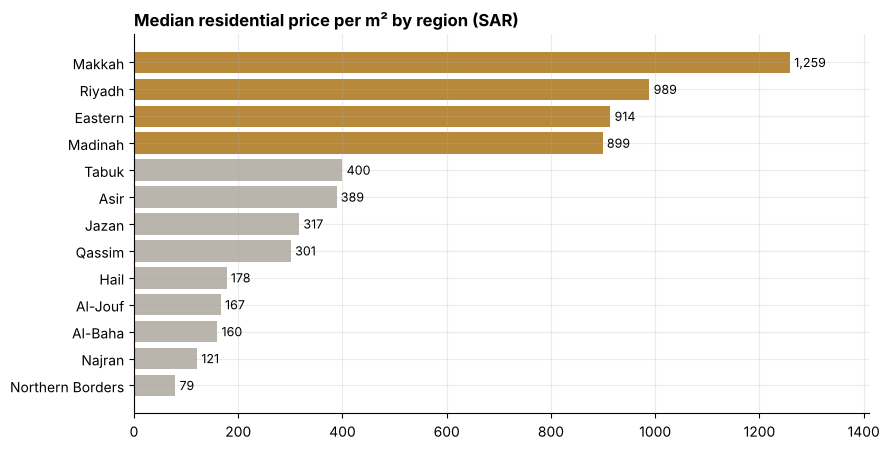

,median,deals
region,,
مكة المكرمة,"1,258.76",240905
الرياض,989.01,389755
الشرقية,914.08,158085
المدينة المنورة,899.26,53407
تبوك,400.00,21158
عسير,388.89,60483
جازان,317.05,28121
القصيم,301.20,104005
حائل,177.78,45599


In [14]:
by_region = res.groupby('region')['price_per_m2'].agg(median='median', deals='size').sort_values('median')
ax = plt.figure(figsize=(9, 4.6)).gca()
bars = ax.barh(to_en(by_region.index), by_region['median'], color=[GOLD if v > 800 else GREY for v in by_region['median']])
ax.bar_label(bars, labels=[f'{v:,.0f}' for v in by_region['median']], padding=3, fontsize=9)
ax.set_title('Median residential price per m² by region (SAR)', loc='left', fontsize=12, weight='bold'); ax.margins(x=.12)
plt.tight_layout(); plt.show()
by_region.sort_values('median', ascending=False)

أربع مناطق بس فوق 800 ريال للمتر: مكة المكرمة والرياض والشرقية والمدينة المنورة. وبعدها فيه فجوة كبيرة، فتبوك وعسير حوالي 400، والحدود الشمالية أقل من 80 ريال.

### أكبر 15 مدينة من حيث عدد الصفقات

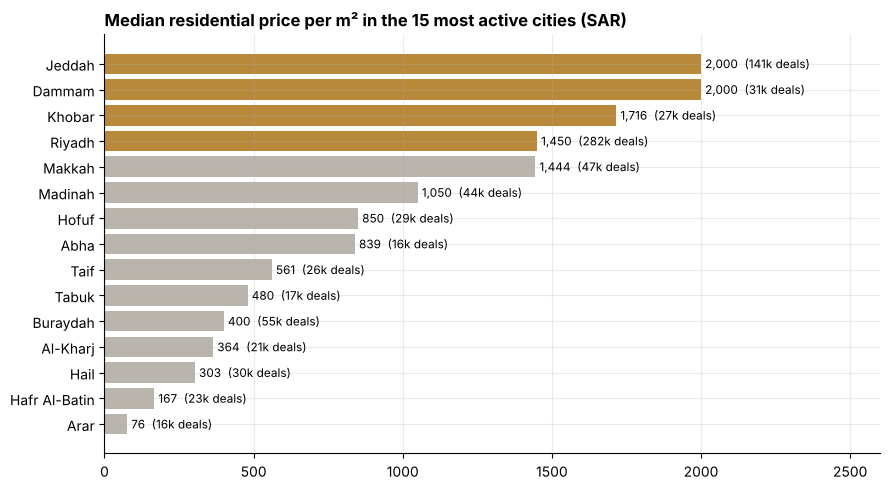

In [15]:
top_cities = res['city'].value_counts().head(15).index
by_city = res[res['city'].isin(top_cities)].groupby('city')['price_per_m2'].agg(median='median', deals='size').sort_values('median')
ax = plt.figure(figsize=(9, 5)).gca()
bars = ax.barh(to_en(by_city.index), by_city['median'], color=[GOLD if c in ['الرياض', 'جده', 'الدمام', 'الخبر'] else GREY for c in by_city.index])
ax.bar_label(bars, labels=[f'{m:,.0f}  ({d/1000:,.0f}k deals)' for m, d in zip(by_city['median'], by_city['deals'])], padding=3, fontsize=8.5)
ax.set_title('Median residential price per m² in the 15 most active cities (SAR)', loc='left', fontsize=12, weight='bold'); ax.margins(x=.3)
plt.tight_layout(); plt.show()

جدة والدمام بالتساوي في الأعلى (2,000 ريال)، بعدها الخبر، ثم الرياض (1,450). الرياض أقل من المتوقع، والسبب إن جزء كبير من صفقاتها في أطراف المدينة، مثل الخير وعريض ونمار، وأغلبها أراضي أرخص، وهذا ينزّل الوسيط.

### داخل الرياض: الأغلى والأرخص

gap between the top and bottom district: 37x


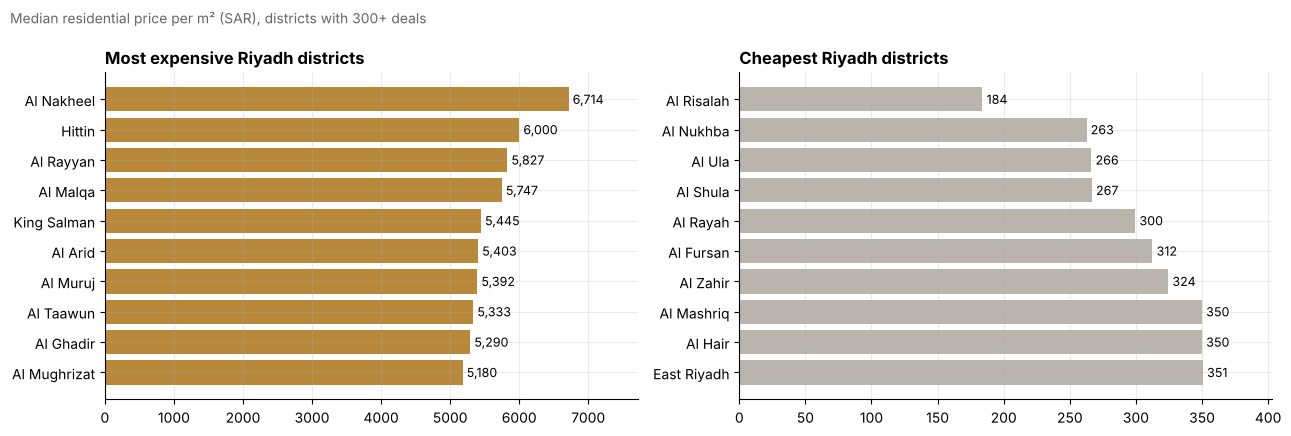

In [16]:
riyadh = res[res['city'] == 'الرياض']
by_district = riyadh.groupby('district')['price_per_m2'].agg(median='median', deals='size')
by_district = by_district[by_district['deals'] >= 300]   # enough deals to trust the median

top10 = by_district.sort_values('median', ascending=False).head(10)
bottom10 = by_district.sort_values('median').head(10)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, t, c, title in [(axes[0], top10, GOLD, 'Most expensive'), (axes[1], bottom10, GREY, 'Cheapest')]:
    t = t.iloc[::-1] if title == 'Most expensive' else t.iloc[::-1]
    b = ax.barh(to_en(t.index), t['median'], color=c)
    ax.bar_label(b, labels=[f'{v:,.0f}' for v in t['median']], padding=3, fontsize=9)
    ax.set_title(f'{title} Riyadh districts', loc='left', fontsize=12, weight='bold'); ax.margins(x=.15)
fig.suptitle('Median residential price per m² (SAR), districts with 300+ deals', x=.01, ha='left', fontsize=10, color='#666')
plt.tight_layout(); plt.show()
print(f'gap between the top and bottom district: {top10["median"].iloc[0] / bottom10["median"].iloc[0]:.0f}x')

In [17]:
# where most deals happen
most_traded = riyadh['district'].value_counts().head(10)
pd.DataFrame({'deals': most_traded, 'median_price_m2': by_district.reindex(most_traded.index)['median']})

,deals,median_price_m2
district,,
الخير,31682,933.33
عريض,20120,666.67
نمار,18209,"1,018.52"
شرق الرياض,14840,350.68
الجنادرية,14394,"1,400.00"
النظيم,13580,"1,300.00"
الرمال,12592,"2,800.00"
النرجس,8261,"5,100.00"
بدر,5799,"1,350.00"


الفرق داخل الرياض نفسها ضخم: أغلى حي (النخيل) حوالي 6,700 ريال للمتر، وأرخص حي حوالي 180، يعني الفرق تقريباً **37 ضعف**. الأحياء الغالية كلها في **شمال الرياض** (حطين، الملقا، النرجس، العارض). أما أكثر الأحياء صفقات فهي في **الأطراف** (الخير، عريض، نمار، شرق الرياض)، وأسعارها أقل بكثير. يعني أغلب الناس يشترون بعيد عن الأحياء الغالية.

### كيف تغيّرت الأسعار مع الوقت

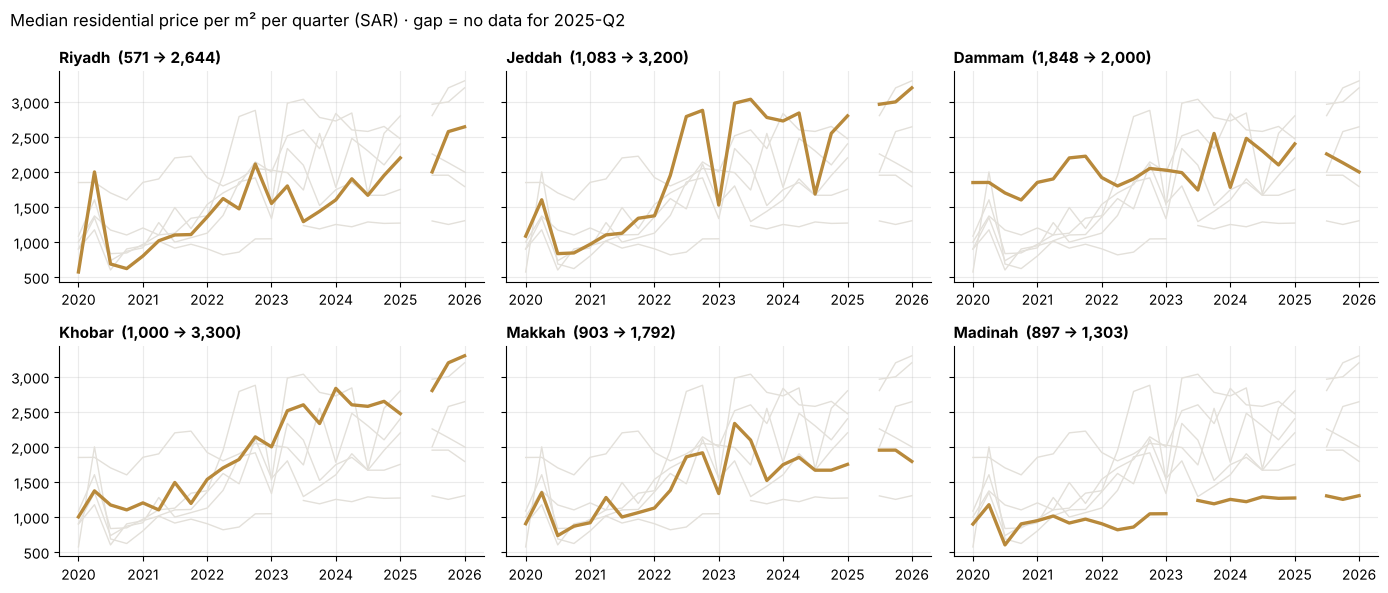

In [18]:
cities6 = ['الرياض', 'جده', 'الدمام', 'الخبر', 'مكة المكرمة', 'المدينة المنورة']
trend = res[res['city'].isin(cities6)].groupby(['quarter', 'city'])['price_per_m2'].median().unstack()
trend = trend.reindex(pd.period_range(trend.index.min(), trend.index.max(), freq='Q'))   # keeps the 2025-Q2 gap visible

fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharey=True)
x = trend.index.to_timestamp()
for ax, c in zip(axes.flat, cities6):
    for other in cities6:
        ax.plot(x, trend[other], color='#E3E0DA', lw=1)
    ax.plot(x, trend[c], color=GOLD, lw=2.4)
    first, last = trend[c].dropna().iloc[[0, -1]]
    ax.set_title(f'{en.get(c, c)}  ({first:,.0f} → {last:,.0f})', loc='left', fontsize=11, weight='bold')
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:,.0f}'))
fig.suptitle('Median residential price per m² per quarter (SAR) · gap = no data for 2025-Q2', x=.01, ha='left', fontsize=12)
plt.tight_layout(); plt.show()

In [19]:
yearly = res.groupby(res['date'].dt.year).agg(deals=('ref', 'size'), median_price_m2=('price_per_m2', 'median'),
                                              total_value_bn=('price', lambda s: s.sum() / 1e9))
yearly

,deals,median_price_m2,total_value_bn
date,,,
2020,235308,387.02,100.74
2021,230075,500.00,115.56
2022,175311,701.00,114.65
2023,146572,782.62,94.78
2024,214431,"1,073.68",148.65
2025,141171,"1,050.18",97.72
2026,28999,960.00,18.85


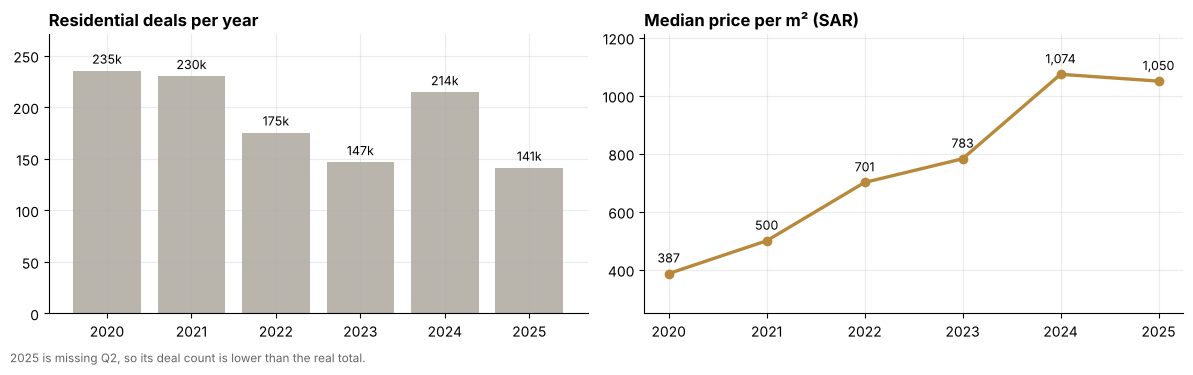

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
full = yearly.loc[2020:2025]
b = axes[0].bar(full.index.astype(str), full['deals'] / 1000, color=GREY)
axes[0].bar_label(b, labels=[f'{v:,.0f}k' for v in full['deals'] / 1000], padding=3, fontsize=9)
axes[0].set_title('Residential deals per year', loc='left', fontsize=12, weight='bold'); axes[0].margins(y=.15)
axes[1].plot(full.index.astype(str), full['median_price_m2'], color=GOLD, lw=2.4, marker='o')
for xi, v in zip(full.index.astype(str), full['median_price_m2']):
    axes[1].annotate(f'{v:,.0f}', (xi, v), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=9)
axes[1].set_title('Median price per m² (SAR)', loc='left', fontsize=12, weight='bold'); axes[1].margins(y=.2)
fig.text(.01, -.02, '2025 is missing Q2, so its deal count is lower than the real total.', fontsize=8.5, color='#666')
plt.tight_layout(); plt.show()

**وش لاحظت في الوقت:**
- على مستوى المملكة، وسيط سعر المتر السكني **تقريباً تضاعف ثلاث مرات** من 2020 (حوالي 390 ريال) إلى 2024 (حوالي 1,070).
- عدد الصفقات نزل من 2021 إلى 2023 (من 230 ألف إلى 147 ألف)، ورجع ارتفع في 2024. يعني الأسعار كانت تطلع حتى لما السوق كان أهدأ.
- أكثر المدن ارتفاعاً: **الرياض** (من حوالي 570 ريال في بداية 2020 إلى أكثر من 2,600 في 2026)، و**جدة** (من حوالي 1,100 إلى 3,200)، و**الخبر** (من 1,000 إلى 3,300).
- **الدمام** ثابتة نسبياً حول 2,000، و**المدينة المنورة** أهدأ مدينة (من حوالي 900 إلى 1,300).
- بس لازم أنتبه: جزء من الارتفاع ممكن يكون بسبب **تغيّر نوع العقارات المباعة** (مثلاً شقق أكثر وأراضي أقل)، مو بس ارتفاع الأسعار نفسها.

## الجزء الثالث: نموذج يتوقع سعر المتر

السؤال: لو عندي صفقة جديدة، أعرف مدينتها وحيّها وتصنيفها ومساحتها وتاريخها، هل أقدر أتوقع سعر المتر؟

**قرارات اتخذتها قبل ما أبدأ:**
- **أتوقع لوغاريتم سعر المتر** بدل السعر نفسه، لأن الأسعار متباعدة جداً (من 3 ريال إلى 9,000)، واللوغاريتم يخلي النموذج يهتم بالنسبة مو بالفرق المطلق.
- **التقسيم زمني**: أدرّب على 2020 إلى 2024، وأختبر على 2025 و2026. لأن في الواقع النموذج بيتوقع صفقات مستقبلية، فالتقسيم العشوائي بيعطي نتيجة أحسن من الحقيقة.
- **الحي فيه أكثر من 11 ألف قيمة**، فما ينفع One-Hot. استخدمت **Target Encoding**، يعني أعوّض كل حي بمتوسط سعره في بيانات التدريب، مع تنعيم للأحياء اللي صفقاتها قليلة.

In [21]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

data = clean[clean['classification'].isin(['سكني', 'تجاري', 'زراعي'])].copy()
data['y'] = np.log(data['price_per_m2'])
data['log_area'] = np.log(data['area'])
data['year'] = data['date'].dt.year
data['quarter_num'] = data['date'].dt.quarter
data['t'] = (data['date'] - pd.Timestamp('2020-01-01')).dt.days / 365.25   # time as a number
data['city_key'] = data['region'] + '|' + data['city']
data['district_key'] = data['city_key'] + '|' + data['district'].fillna('')   # same district name exists in different cities
data['is_commercial'] = (data['classification'] == 'تجاري').astype(int)
data['is_agri'] = (data['classification'] == 'زراعي').astype(int)

train = data[data['year'] <= 2024].copy()
test = data[data['year'] >= 2025].copy()
print(f'train: {len(train):,} deals (2020–2024) | test: {len(test):,} deals (2025–2026)')

train: 1,168,940 deals (2020–2024) | test: 186,022 deals (2025–2026)


### Target Encoding بدون تسريب
لو حسبت متوسط الحي من نفس الصفوف اللي أدرّب عليها، النموذج بيشوف الجواب وهو يتعلّم (Data Leakage). فقسمت بيانات التدريب لخمس أجزاء، وكل جزء حسبت له المتوسط من الأجزاء الثانية بس.

In [22]:
def smooth_mean(df, key, target='y', k=20):
    g = df.groupby(key)[target].agg(['mean', 'count'])
    prior = df[target].mean()
    return (g['mean'] * g['count'] + prior * k) / (g['count'] + k), g['count'], prior

def target_encode(train, test, key, k=20):
    oof = pd.Series(np.nan, index=train.index)
    for tr_idx, va_idx in KFold(5, shuffle=True, random_state=42).split(train):
        enc, _, prior = smooth_mean(train.iloc[tr_idx], key, k=k)
        oof.iloc[va_idx] = train.iloc[va_idx][key].map(enc).fillna(prior).values
    enc, counts, prior = smooth_mean(train, key, k=k)
    return oof, test[key].map(enc).fillna(prior), test[key].map(counts).fillna(0), train[key].map(counts)

for key in ['district_key', 'city_key']:
    tr_enc, te_enc, te_cnt, tr_cnt = target_encode(train, test, key)
    train[f'{key}_te'], test[f'{key}_te'] = tr_enc, te_enc
    train[f'{key}_n'], test[f'{key}_n'] = np.log1p(tr_cnt), np.log1p(te_cnt)

features = ['district_key_te', 'city_key_te', 'district_key_n', 'city_key_n',
            'log_area', 't', 'quarter_num', 'is_commercial', 'is_agri']
train[features].describe().T[['mean', 'min', 'max']]

,mean,min,max
district_key_te,6.25,2.29,8.64
city_key_te,6.24,3.11,7.69
district_key_n,6.83,0.69,10.35
city_key_n,10.42,0.69,12.55
log_area,6.30,0.43,16.99
t,2.37,0.00,5.00
quarter_num,2.47,1.00,4.00
is_commercial,0.11,0.00,1.00
is_agri,0.03,0.00,1.00


### خط الأساس
قبل النموذج، لازم أعرف وش النتيجة اللي "سهل" أوصل لها: أتوقع لكل صفقة **وسيط سعر المتر في حيّها** من بيانات التدريب. إذا النموذج ما تفوّق على هذا، ما له فايدة.

In [23]:
def report(name, y_true_log, y_pred_log):
    true, pred = np.exp(y_true_log), np.exp(y_pred_log)
    ape = np.abs(pred - true) / true
    return {'model': name,
            'R² (log)': r2_score(y_true_log, y_pred_log),
            'MAE (SAR/m²)': mean_absolute_error(true, pred),
            'median error %': np.median(ape) * 100,
            'within ±25%': (ape <= .25).mean() * 100}

district_median = train.groupby('district_key')['y'].median()
city_median = train.groupby('city_key')['y'].median()
baseline = test['district_key'].map(district_median).fillna(test['city_key'].map(city_median)).fillna(train['y'].median())
results = [report('Baseline: district median', test['y'], baseline)]
pd.DataFrame(results).set_index('model')

,R² (log),MAE (SAR/m²),median error %,within ±25%
model,,,,
Baseline: district median,0.68,663.63,37.58,35.20


### النموذج: Gradient Boosting

In [24]:
model = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.08, max_leaf_nodes=63,
                                      min_samples_leaf=100, l2_regularization=1.0, random_state=42)
model.fit(train[features], train['y'])
test['pred'] = model.predict(test[features])

results.append(report('Gradient Boosting', test['y'], test['pred']))
scores = pd.DataFrame(results).set_index('model')
scores

,R² (log),MAE (SAR/m²),median error %,within ±25%
model,,,,
Baseline: district median,0.68,663.63,37.58,35.20
Gradient Boosting,0.77,537.58,29.77,44.07


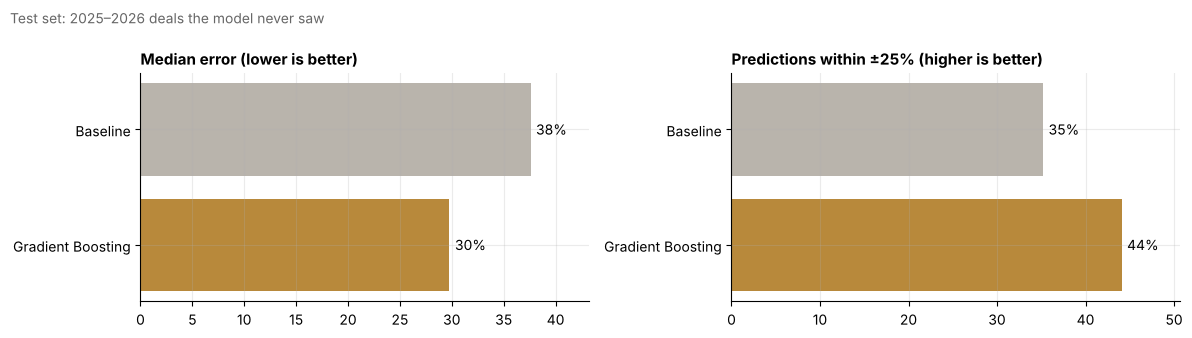

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, col, fmt in [(axes[0], 'median error %', '{:.0f}%'), (axes[1], 'within ±25%', '{:.0f}%')]:
    b = ax.barh(['Baseline', 'Gradient Boosting'], scores[col], color=[GREY, GOLD])
    ax.bar_label(b, labels=[fmt.format(v) for v in scores[col]], padding=4)
    ax.set_title(col.replace('median error %', 'Median error (lower is better)').replace('within ±25%', 'Predictions within ±25% (higher is better)'),
                 loc='left', fontsize=11, weight='bold'); ax.margins(x=.15); ax.invert_yaxis()
fig.suptitle('Test set: 2025–2026 deals the model never saw', x=.01, ha='left', fontsize=10, color='#666')
plt.tight_layout(); plt.show()

### وش أهم العوامل؟

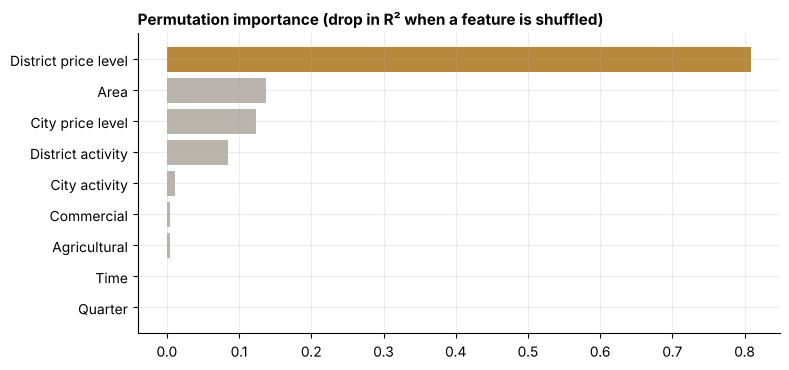

district_key_te    0.81
log_area           0.14
city_key_te        0.12
district_key_n     0.08
city_key_n         0.01
is_commercial      0.00
is_agri            0.00
t                  0.00
quarter_num       -0.00
dtype: float64

In [26]:
sample = test.sample(30000, random_state=1)
imp = permutation_importance(model, sample[features], sample['y'], n_repeats=3, random_state=1, scoring='r2')
importance = pd.Series(imp.importances_mean, index=features).sort_values()
names = {'district_key_te': 'District price level', 'city_key_te': 'City price level', 'log_area': 'Area',
         't': 'Time', 'district_key_n': 'District activity', 'city_key_n': 'City activity',
         'quarter_num': 'Quarter', 'is_commercial': 'Commercial', 'is_agri': 'Agricultural'}
ax = plt.figure(figsize=(8, 3.8)).gca()
b = ax.barh([names[f] for f in importance.index], importance, color=[GOLD if v == importance.max() else GREY for v in importance])
ax.set_title('Permutation importance (drop in R² when a feature is shuffled)', loc='left', fontsize=11, weight='bold')
plt.tight_layout(); plt.show()
importance.sort_values(ascending=False).round(3)

### وين يغلط النموذج أكثر؟

In [27]:
test['ape'] = np.abs(np.exp(test['pred']) - test['price_per_m2']) / test['price_per_m2']
err_city = test[test['city'].isin(cities6)].groupby('city')['ape'].median().mul(100).sort_values()
err_class = test.groupby('classification')['ape'].median().mul(100)
err_size = test.groupby(pd.qcut(test['area'], 4, labels=['small', 'medium', 'large', 'very large']), observed=True)['ape'].median().mul(100)
display(err_city.rename('median error %').to_frame().rename(index=en))
display(err_class.rename('median error %').to_frame())
err_size.rename('median error %').to_frame()

,median error %
city,
Jeddah,15.67
Makkah,20.99
Khobar,21.23
Dammam,21.53
Madinah,23.48
Riyadh,24.50


,median error %
classification,
تجاري,36.39
زراعي,47.87
سكني,28.86


,median error %
area,
small,23.57
medium,29.70
large,33.36
very large,35.10


**وش طلع معي:**
- النموذج تفوّق على خط الأساس بوضوح: **R² ارتفع من 0.68 إلى 0.77**، والخطأ الوسيط نزل من **38% إلى 30%**، ونسبة التوقعات اللي ضمن ±25% ارتفعت من 35% إلى **44%**.
- أهم عامل بفارق كبير هو **مستوى أسعار الحي**، بعده **المساحة** ثم **المدينة**. يعني الموقع هو كل شي تقريباً في العقار.
- **الوقت ما أثّر في النموذج.** وهذا متوقع، لأن نماذج الأشجار ما تقدر تتوقع قيم خارج المدى اللي تدرّبت عليه، فما تعرف إن الأسعار بتكمل ترتفع بعد 2024. لو أبي أحسّن هذا، ممكن أتوقع التغيّر عن مستوى الحي بدل السعر نفسه.
- النموذج أدق في **جدة** (خطأ 16%) وأضعف في **الرياض** (25%)، لأن الرياض أكثر تنوّع داخل الحي الواحد. وأدق مع **العقارات الصغيرة** والسكنية، وأضعف مع الأراضي الزراعية والمساحات الكبيرة.

**حدود النموذج:** خطأ 30% مو قليل، والسبب الأساسي إن البيانات **ما فيها نوع العقار** (أرض، شقة، فيلا) ولا عمر المبنى ولا مواصفاته. شقة وأرض في نفس الحي سعر مترهم مختلف تماماً، والنموذج ما يقدر يفرّق بينهم. فهو يصلح كتقدير أولي لمستوى السعر في المنطقة، مو كتثمين دقيق لعقار معيّن.

## الخلاصة

اشتغلت على حوالي **1.36 مليون صفقة بيع** مسجلة في وزارة العدل من 2020 إلى 2026، وهذا أهم اللي طلعت فيه:

1. **السوق متركّز في أربع مناطق.** مكة المكرمة والرياض والشرقية والمدينة المنورة بس فوق 800 ريال للمتر، والباقي أقل بكثير.
2. **الفرق داخل المدينة الوحدة أكبر من الفرق بين المدن.** في الرياض، أغلى حي أغلى من أرخص حي بحوالي 37 ضعف. والأحياء الغالية كلها في الشمال، بينما أكثر الصفقات تصير في الأطراف.
3. **الأسعار تقريباً تضاعفت ثلاث مرات من 2020 إلى 2024**، حتى في السنوات اللي قلّت فيها الصفقات. والرياض وجدة والخبر أكثر المدن ارتفاعاً.
4. **الموقع هو العامل الأهم في السعر.** النموذج اللي بنيته يعتمد على مستوى أسعار الحي أكثر من أي شي ثاني، ووصل لـ R² = 0.77 على صفقات 2025–2026 اللي ما شافها.

**أشياء تعلمتها من البيانات نفسها:**
- أعمدة الملفات تتغيّر بين السنوات، وأسماء المناطق مكتوبة بأكثر من طريقة.
- ملف 2025-Q2 طلع نسخة من 2024-Q2، فما فيه بيانات فعلية لذاك الربع.
- غياب نوع العقار (أرض، شقة، فيلا) هو أكبر قيد على التحليل والنموذج.

**لو أكمل المشروع:**
- أدمج بيانات الهيئة العامة للعقار اللي فيها نوع العقار، عشان أفصل الشقق عن الأراضي.
- أجرّب أتوقع التغيّر في السعر بدل السعر نفسه، عشان النموذج يتعامل مع ارتفاع الأسعار مع الوقت.
- أسوي لوحة Power BI تفاعلية للأحياء.

**المصدر:** وزارة العدل، عبر منصة البيانات المفتوحة السعودية (open.data.gov.sa)، بموجب رخصة البيانات المفتوحة.